# Proximal benchmark sampler: v2 (`smoothA`) and v3 (`smoothA_a350`)

```
       Based on: "Collecting data from custom graphs for proximal learning" (Juan L. Gamella, 2026.04.23)
  Benchmark by: Ayub Kharel, Jakob Zeitler, Christophe Muller
```

This notebook produces the 12-setting causal chamber benchmark (`v2_smoothA`, treatment LED level 500)
and (`v3_a350`, treatment LED level 350).

**Settings**: confounding {weak, strong} x mechanisms {linear, non_linear} x proxy informativeness {low, mid, high}, N = 1000 each.

**Variable roles** (light tunnel): U = `green` (drive value of the `blue` LED in strong settings), X = `red`, W = `pol_1` (outcome proxy),
Z = `led_2_uv` (treatment proxy), A = `led_3_uv > 0`, Y = `ir_3`, counterfactuals `Y0`, `Y1`, true propensity `pA`.
`current_ls_raw`, `vis_1`, `ir_1`, `ir_2`, `pol_2` are intermediates kept for diagnostics.

**Mechanism**
- X = round(f1(current_ls_raw))
- W = clip(f4(vis_1) + sd_W * e_W, -180, 180), written to the polariser (so the noise is physical, not post-hoc)
- Z = clip(round(f2(ir_1) + sd_Z * e_Z), 0, 4095), written to `led_2_uv`
- pol_2 = pol_1 + 90 (wrapped into [-180, 180]) in weak settings, 0 in strong settings
- pA = 1 / (1 + exp(-(c - ir_2) / s)), A = 1{u < pA}, `led_3_uv` = A x level (500 for v2, 350 for v3)
- Y = `ir_3` under the assigned treatment; then `led_3_uv` is forced to 0 and re-measured (Y0), then to the treatment level (Y1)
- `green`, e_W, e_Z and u are drawn once per setting from fixed seeds, so all 12 files share the same draws (as in the released data)


Physical sensor readings will of course differ on every run.

To run this notebook you will also need matplotlib, numpy, and seaborn, although these are not a dependency of the `causalchamber` package.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Connect to the Remote Lab

If you haven't already, set up your credentials following these [instructions](https://docs.causalchamber.ai/remote-lab/quickstart).

In [ ]:
import causalchamber.lab

In [ ]:
import causalchamber.lab as lab
CREDENTIALS = 'cc_key.txt'  # path to your Remote Lab key
rlab = lab.Lab(CREDENTIALS)

## Defining a custom graph

You can exclude the variables `current_ls_raw`, `ir_1`, `vis_1` and `ir_2` from your dataset (i.e., unobserved), and the graph collapses to the star-shaped graph from Tchetgen et al. (2020, [PDF](https://arxiv.org/pdf/2009.10982)).

You are free to define the functions `f_1`, ..., `f_4` how you wish (or even turn them off). See some examples below.

Define how sampling is done with the functions `sample_standard` or `sample_linked` below. You can edit them to suit your needs or sample from other graphs.

**Why two functions?**

- `sample_standard` uses the chamber in the `standard` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_standard.pdf)) configuration, i.e., the digital effects (green edges) are implemented by you in the `sample_standard` function.
- `sample_linked` uses the configurations `linked_leds` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds.pdf)) or `linked_leds_sigmoid` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds_sigmoid.pdf)), where the functions `f2` and `f3` are already implemented by the microcontroller of the chamber. This means slightly faster sampling, but limits the forms of these functions to a clamped linear function or a logistic function (sigmoid). You can change the paramters of these functions (see interventions below).

To learn more about hardware configurations, see [here](https://docs.causalchamber.ai/the-chambers/how-they-work#hardware-configurations).

#### Interventions

For sensor measurements (marked with M), only perturbations are possible (by changing the sensor parameters). See the [documentation](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_standard.pdf) for the complete chamber graph and variable descriptions.

For input nodes (marked with I).

- If running the `standard` configuration: You can perform any intervention type on input nodes, just adjust the `sample_standard` function below
- If running the `linked_leds` or `linked_leds_sigmoid` configurations: use the variables [`slope/intercept_f2/3, intercept_f2/3`](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds.pdf) or [`l/k/x0/b_f2/f3`](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds_sigmoid.pdf) to perform interventions on `led_2_uv` and `led_3_uv`.

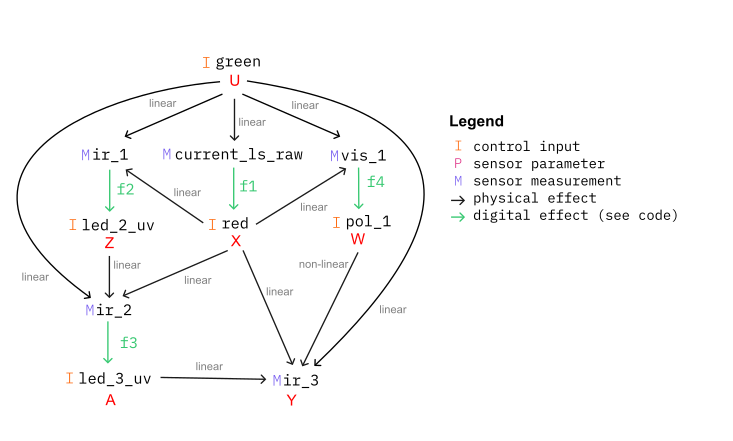

### Defining `f_1`, ..., `f_4`

You can use whatever you like, but here are two pre-implemented ones: a clamped linear function and a parametrizable sigmoid (the logistic function).

#### Clamped linear function

In [ ]:
def clamped(x, a, b, lo, hi):
    return np.maximum(lo,np.minimum(hi, a*x + b))

The parameters `a`,`b` are the slope and intercept, `lo`,`hi` set the max/min values (at which clamping ocurrs).

#### Logistic function

In [ ]:
def logistic(x, l, k, x0, b):
    return l / (1 + np.exp(-k * (x-x0))) + b    

The parameters `l`,`k`,`x0` and `b` allow you to change the shape of the function. See appendix for different function shapes.

### Collecting data

To understand the chamber / batch calls, please see the [documentation](https://docs.causalchamber.ai/remote-lab/running-a-real-time-experiment).

To sample using the `standard` configuration of the chamber ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_standard.pdf)).

In [ ]:
def sample_standard(chamber, green, f1, f2, f3, f4):
    # Step 0: reset all inputs (see https://docs.causalchamber.ai/case-studies/causal-inference/generating-real-data-with-a-known-causal-structure#a-note-of-caution)
    batch = chamber.new_batch()
    batch.set('green', 0)
    batch.set('red', 0)
    batch.set('led_2_uv', 0)
    batch.set('pol_1', 0)
    batch.set('led_3_uv', 0)
    
    # Step 1: Set green, then measure
    batch = chamber.new_batch()
    batch.set('green', green)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 2: Set red (from step 1's measurement), then measure
    current_ls_raw = df.current_ls_raw
    red = round(f1(current_ls_raw))
    batch = chamber.new_batch()
    batch.set('red', red)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 3: Set led_2_uv and pol_1 (from step 2's measurement), then measure
    ir_1 = df.ir_1
    led_2_uv = round(f2(ir_1))
    vis_1 = df.vis_1
    pol_1 = f4(vis_1)
    batch = chamber.new_batch()
    batch.set('led_2_uv', led_2_uv)
    batch.set('pol_1', pol_1)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 4: Set led_3_uv (from step 3's measurement), then measure
    ir_2 = df.ir_2
    led_3_uv = round(f3(ir_2))
    batch = chamber.new_batch()
    batch.set('led_3_uv', led_3_uv)
    batch.measure(n=1)
    df = batch.submit().iloc[0]
    ir_3 = df.ir_3

    # Return data
    return pd.DataFrame({
        'green': [green],
        'current_ls_raw': [current_ls_raw],
        'red': [red],        
        'vis_1': [vis_1],
        'pol_1': [pol_1],
        'ir_1': [ir_1],
        'led_2_uv': [led_2_uv],
        'ir_2': [ir_2],
        'led_3_uv': [led_3_uv],
        'ir_3': [ir_3]
    })

To sample using the `linked_leds` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds.pdf)) or `linked_leds_sigmoid` ([docs](https://cchamber-box.s3.eu-central-2.amazonaws.com/config_doc_lt_mk2_linked_leds_sigmoid.pdf)) configurations of the chamber.

In [ ]:
def sample_linked(chamber, green, f1, f4):
    # Step 0: reset all inputs (see https://docs.causalchamber.ai/case-studies/causal-inference/generating-real-data-with-a-known-causal-structure#a-note-of-caution)
    batch = chamber.new_batch()
    batch.set('green', 0)
    batch.set('red', 0)
    batch.set('led_2_uv', 0)
    batch.set('pol_1', 0)
    batch.set('led_3_uv', 0)
    
    # Step 1: Set green, then measure
    batch = chamber.new_batch()
    batch.set('green', green)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 2: Set red (from step 1's measurement), then measure
    current_ls_raw = df.current_ls_raw
    red = round(f1(current_ls_raw))    
    batch = chamber.new_batch()
    batch.set('red', red)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 3: Set pol_1 (from step 2's measurement), then measure
    # NOTE: f2, f3 are computed by the chamber itself
    vis_1 = df.vis_1
    pol_1 = f4(vis_1)
    batch = chamber.new_batch()
    batch.set('pol_1', pol_1)
    batch.measure(n=1)
    df_last = batch.submit().iloc[0]

    # Return data
    return pd.DataFrame({
        'green': [green],
        'current_ls_raw': [current_ls_raw],
        'red': [red],
        'vis_1': [vis_1],
        'pol_1': [pol_1],
        'ir_1': [df_last.ir_1],
        'led_2_uv': [df_last.led_2_uv],
        'ir_2': [df_last.ir_2],
        'led_3_uv': [df_last.led_3_uv],
        'ir_3': [df_last.ir_3]
    })

## Benchmark definition

Edges, settings, proxy-noise levels and the treatment mechanism. `f2` in the strong non-linear setting uses `l = 1000` (the template uses 4095).

In [ ]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Software edges f1..f4 (same parameterisation as Juan's template)
# ---------------------------------------------------------------------------
def clamped(x, a, b, lo, hi):
    return np.maximum(lo, np.minimum(hi, a * x + b))

def logistic(x, l, k, x0, b):
    return l / (1 + np.exp(-k * (x - x0))) + b

f1_linear      = lambda x: clamped(x, -0.085, -1445, 0, 255)                 # X = red
f1_non_linear  = lambda x: logistic(x, l=255, k=2e-3, x0=-19000.0, b=0)
f2_linear      = lambda x: clamped(x, 0.0624, 0, 0, 4095)                    # Z = led_2_uv (clean part)
f2_non_linear  = lambda x: logistic(x, l=4095, k=1e-3, x0=35000.0, b=0)
f2_non_linear_strong = lambda x: logistic(x, l=1000, k=1e-3, x0=35000.0, b=0)  # l=1000 in the strong non-linear setting
f4             = lambda x: logistic(x, l=180, k=2e-3, x0=4000, b=-90)        # W = pol_1 (clean part)

# ---------------------------------------------------------------------------
# Benchmark settings (4 DGPs x 3 proxy levels = 12 files per treatment level)
#   treatment: A ~ Bernoulli(pA), pA = 1 / (1 + exp(-(c - ir_2) / s))   ("smoothA")
#   max_confounding: drive the confounder LED 'blue' instead of 'green', pol_2 = 0
# ---------------------------------------------------------------------------
SETTINGS = {
    "weak_confounding_linear":       dict(f1=f1_linear,     f2=f2_linear,            max_confounding=False, c=5250, s=800),
    "weak_confounding_non_linear":   dict(f1=f1_non_linear, f2=f2_non_linear,        max_confounding=False, c=8789, s=2000),
    "strong_confounding_linear":     dict(f1=f1_linear,     f2=f2_linear,            max_confounding=True,  c=5250, s=800),
    "strong_confounding_non_linear": dict(f1=f1_non_linear, f2=f2_non_linear_strong, max_confounding=True,  c=3930, s=800),
}

# Proxy "informativeness": Gaussian noise added to the proxy *before* it is written to the
# actuator, with sd = multiplier x reference SD of the clean proxy for that setting.
PROXY_LEVELS = {"high": 0.0, "mid": 0.75, "low": 2.0}
# strong linear 'low' was recalibrated: W uses 2.5, Z uses 0.6
PROXY_LEVEL_OVERRIDES = {("strong_confounding_linear", "low"): dict(W=2.5, Z=0.6)}

# Reference SDs of the clean proxies (W = f4(vis_1), Z = f2(ir_1)) per setting.
# W values are recovered exactly (to 0.1) from the v2/v3 files; Z values are recovered up to a
# common ~2% scale factor (the original noise seed is lost) -- ratios between settings are exact.
PROXY_SD = {
    "weak_confounding_linear":       dict(W=62.2, Z=317.8),
    "strong_confounding_linear":     dict(W=66.2, Z=374.5),
    "strong_confounding_non_linear": dict(W=62.6, Z=402.8),
    "weak_confounding_non_linear":   dict(W=64.5, Z=1749.3),
}

def noise_sds(setting, level):
    mW = mZ = PROXY_LEVELS[level]
    o = PROXY_LEVEL_OVERRIDES.get((setting, level))
    if o:
        mW, mZ = o["W"], o["Z"]
    return mW * PROXY_SD[setting]["W"], mZ * PROXY_SD[setting]["Z"]

# ---------------------------------------------------------------------------
# Software edges with noise (pure functions, reused by the offline check below)
# ---------------------------------------------------------------------------
def edge_X(setting, current_ls_raw):
    return np.round(SETTINGS[setting]["f1"](current_ls_raw))

def edge_W(vis_1, sd, e):
    return np.clip(f4(vis_1) + sd * e, -180, 180)

def edge_Z(setting, ir_1, sd, e):
    return np.clip(np.round(SETTINGS[setting]["f2"](ir_1) + sd * e), 0, 4095)

def edge_pol_2(setting, pol_1):
    if SETTINGS[setting]["max_confounding"]:
        return 0 * pol_1
    return np.where(pol_1 + 90 <= 180, pol_1 + 90, pol_1 - 90)   # crossed polariser, kept in [-180, 180]

def propensity(setting, ir_2):
    c, s = SETTINGS[setting]["c"], SETTINGS[setting]["s"]
    return 1 / (1 + np.exp(-(c - ir_2) / s))

## Sampling one data point (with counterfactuals)

The chamber call sequence follows the template's `sample_standard_binary_treatment_counterfactuals`, with the proxy noise injected
before W and Z are written to the actuators, and the smooth treatment assignment.

**Note on the reset step.** In the template (and in the code that produced v2/v3), the "Step 0" batch that resets the inputs and,
in strong settings, sets max diode size and exposure time for `ir_2`/`ir_3` is created but never submitted, so it has no effect. The data are
consistent with this: Y1 - Y0 is about the same in weak and strong settings (about 889 at level 500), which would not be the case if `ir_3` ran at
higher gain in the strong settings. `SUBMIT_RESET = False` reproduces v2/v3. Set it to `True` to apply the reset and sensor settings as intended. This changes the data.

In [ ]:
SUBMIT_RESET = False   # False reproduces v2/v3 (see note above)

def sample_counterfactual(chamber, setting, green, eW, eZ, u, sdW, sdZ, a1_level):
    cfg = SETTINGS[setting]
    max_confounding = cfg["max_confounding"]

    # Step 0: reset inputs; sensor sensitivity for strong settings
    batch = chamber.new_batch()
    batch.set('green', 0)
    batch.set('blue', 0)
    batch.set('red', 0)
    batch.set('led_2_uv', 0)
    batch.set('pol_1', 0)
    batch.set('pol_2', 0)
    batch.set('led_3_uv', 0)
    batch.set('diode_ir_2', 2 if max_confounding else 0)  # max diode size
    batch.set('diode_ir_3', 2 if max_confounding else 0)
    batch.set('t_ir_2', 3 if max_confounding else 0)      # max exposure time
    batch.set('t_ir_3', 3 if max_confounding else 0)
    if SUBMIT_RESET:
        batch.submit()

    # Step 1: confounder U (blue LED in strong settings, green otherwise), then measure
    batch = chamber.new_batch()
    batch.set('blue' if max_confounding else 'green', green)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 2: X = red = f1(current_ls_raw), then measure
    current_ls_raw = df.current_ls_raw
    red = int(edge_X(setting, current_ls_raw))
    batch = chamber.new_batch()
    batch.set('red', red)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 3: Z = led_2_uv = f2(ir_1) + noise, W = pol_1 = f4(vis_1) + noise, pol_2; then measure
    ir_1, vis_1 = df.ir_1, df.vis_1
    led_2_uv = int(edge_Z(setting, ir_1, sdZ, eZ))
    pol_1 = float(edge_W(vis_1, sdW, eW))
    pol_2 = float(edge_pol_2(setting, pol_1))
    batch = chamber.new_batch()
    batch.set('led_2_uv', led_2_uv)
    batch.set('pol_1', pol_1)
    batch.set('pol_2', pol_2)
    batch.measure(n=1)
    df = batch.submit().iloc[0]

    # Step 4: A ~ Bernoulli(pA), pA = logistic((c - ir_2) / s); set led_3_uv, measure Y = ir_3
    ir_2 = df.ir_2
    pA = float(propensity(setting, ir_2))
    A = int(u < pA)
    led_3_uv = A * a1_level
    batch = chamber.new_batch()
    batch.set('led_3_uv', led_3_uv)
    batch.measure(n=1)
    ir_3 = batch.submit().iloc[0].ir_3

    # Step 5: counterfactuals, forcing led_3_uv to 0 then to the treatment level
    batch = chamber.new_batch()
    batch.set('led_3_uv', 0)
    batch.measure(n=1)
    Y0 = batch.submit().iloc[0].ir_3

    batch = chamber.new_batch()
    batch.set('led_3_uv', a1_level)
    batch.measure(n=1)
    Y1 = batch.submit().iloc[0].ir_3

    return dict(green=green, current_ls_raw=current_ls_raw, red=red, vis_1=vis_1, pol_1=pol_1, pol_2=pol_2,
                ir_1=ir_1, led_2_uv=led_2_uv, ir_2=ir_2, pA=pA, led_3_uv=led_3_uv, ir_3=ir_3, Y1=Y1, Y0=Y0)

## Full benchmark loop

`A1_LEVEL = 500` with suffix `smoothA` gives v2. `A1_LEVEL = 350` with suffix `smoothA_a350` gives v3.
For reference, about 6 s per data point means each file takes about 1h40, and 12 files take about 20 h.

In [ ]:
CHAMBER_ID = 'lt-demo-ch4lu'
N = 1000
GREEN_SEED = 981264976135   
NOISE_SEED = 20260825       
A1_LEVEL, SUFFIX = 350, "smoothA_a350"   # v3 (final batch); use (500, "smoothA") for v2
OUT_DIR = "."

def draws():
    """Same draws for every setting/level, as in the released data."""
    green = np.random.default_rng(GREEN_SEED).integers(0, 256, size=N)
    g = np.random.default_rng(NOISE_SEED)
    eW, eZ, u = g.standard_normal(N), g.standard_normal(N), g.random(N)
    return green, eW, eZ, u

def run(setting, level, verbose=True):
    green, eW, eZ, u = draws()
    sdW, sdZ = noise_sds(setting, level)
    chamber = lab.Chamber(CHAMBER_ID, 'standard', credentials_file=CREDENTIALS)
    rows = []
    for i in range(N):
        if verbose:
            print(f'{setting} / proxy {level}: {i+1}/{N}', end='\r')
        rows.append(sample_counterfactual(chamber, setting, int(green[i]), eW[i], eZ[i], u[i], sdW, sdZ, A1_LEVEL))
    df = pd.DataFrame(rows)
    fn = f"{OUT_DIR}/out_binaryA_counterfactuals_{setting}_proxy_{level}_{SUFFIX}.csv"
    df.to_csv(fn, index=False)
    print(f"\nsaved {fn}  |  P(A=1)={(df.led_3_uv > 0).mean():.3f}  ATE={np.mean(df.Y1 - df.Y0):.1f}")
    return df

In [ ]:
%%time
for setting in SETTINGS:
    for level in PROXY_LEVELS:
        run(setting, level)

## Appendix

The logistic function for different values of the parameters (from the template).

In [ ]:
colors = ["#648FFF", "#785EF0", "#DC267F", "#FE6100", "#FFB000", "black", "green", "blue"]  # IBM colorblind palette

curves = [
    ({"l": 4095, "k": 2e-4, "x0": 32768, "b": 0}, "default params."),
    ({"l": 4095, "k": 1e-4, "x0": 20_000, "b": 0}, "k = 1e-4"),
    ({"l": 4095, "k": -2e-4, "x0": 32768, "b": 0}, "k = -2e-4"),
    ({"l": 25_000, "k": 1e-5, "x0": 32768, "b": -10450}, "k = 1e-5, b = -10450"),
    ({"l": 4095, "k": 1e-2, "x0": 25_000, "b": 0}, "k = 1e-2, x0 = 25e4"),
    #({"l": 4095, "k": 0, "x0": 32768, "b": 0}, "k = 0"),
    ({"l": 255, "k": 2e-3, "x0": -19000, "b": 0}, "f1_non_linear"),
    ({"l": 4095, "k": 1e-3, "x0": 35000, "b": 0}, "f2_non_linear"),
    #f1_non_linear = lambda x: logistic(x, l=255, k=2e-3, x0=-18250.0, b=0) # Logistic
]

x = np.linspace(-21e3, 2**16 - 1, 10_000)
#x = np.linspace(-21e3, -17000, 10_000)

fig, ax = plt.subplots(figsize=(4.7, 3.8))

for i, (params, label) in enumerate(curves):
    ax.plot(x, logistic(x, **params), color=colors[i], label=label)

ax.axhline(0, color="gray", linestyle=":")
ax.axhline(4095, color="gray", linestyle=":")
ax.yaxis.tick_right()
ax.yaxis.set_label_position('right')
ax.set_yticks([0, 4095])
ax.legend(fontsize=9, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2)
ax.set_xlabel('x', fontsize=11)
ax.set_ylabel('$f_n$(x)', rotation=0, ha='right', fontsize=11)
# plt.savefig('sigmoids_params.pdf', dpi=200, bbox_inches='tight')